In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

In [2]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

In [3]:
df = pd.read_csv('netflix_customer_churn.csv')
df.drop(['customer_id'], axis = 1, inplace = True)
df.sample()

,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,churned,payment_method,number_of_profiles,avg_watch_time_per_day,favorite_genre
2224,56,Female,Basic,2.54,39,North America,Desktop,8.99,1,PayPal,5,0.06,Sci-Fi


In [4]:
df.columns

Index(['age', 'gender', 'subscription_type', 'watch_hours', 'last_login_days',
       'region', 'device', 'monthly_fee', 'churned', 'payment_method',
       'number_of_profiles', 'avg_watch_time_per_day', 'favorite_genre'],
      dtype='object')

In [5]:
df['churned'].value_counts()

churned
1    2515
0    2485
Name: count, dtype: int64

In [6]:
df['watch_hours'].describe()

count    5000.000000
mean       11.649450
std        12.014654
min         0.010000
25%         3.337500
50%         8.000000
75%        16.030000
max       110.400000
Name: watch_hours, dtype: float64

In [7]:
ordinal_cols = ['subscription_type']
ordinal_categories = [['Basic', 'Standard', 'Premium']] 

nominal_cols = ['gender', 'region', 'device', 'payment_method', 'favorite_genre']

preprocessor = ColumnTransformer(
    transformers=[
        ('ord', OrdinalEncoder(categories=ordinal_categories), ordinal_cols),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), nominal_cols)
    ],
    remainder='passthrough'
)

encoded_array = preprocessor.fit_transform(df)

encoded_feature_names = preprocessor.get_feature_names_out()
cleaned_feature_names = [name.split('__')[-1] for name in encoded_feature_names]

df = pd.DataFrame(encoded_array, columns=cleaned_feature_names)

In [8]:
df.sample()

,subscription_type,gender_Male,gender_Other,region_Asia,region_Europe,region_North America,region_Oceania,region_South America,device_Laptop,device_Mobile,...,favorite_genre_Horror,favorite_genre_Romance,favorite_genre_Sci-Fi,age,watch_hours,last_login_days,monthly_fee,churned,number_of_profiles,avg_watch_time_per_day
2073,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,1.0,36.0,1.82,55.0,8.99,1.0,2.0,0.03


<Axes: xlabel='watch_hours'>

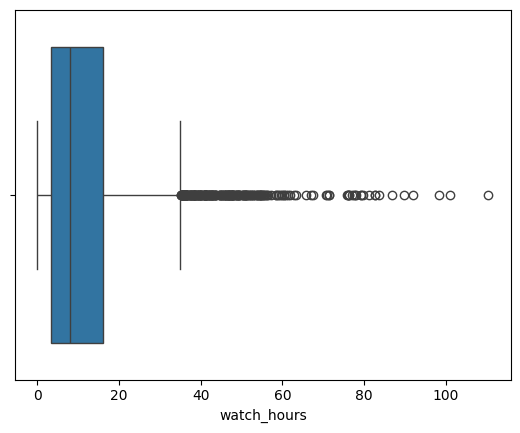

In [9]:
sns.boxplot(data = df, x = 'watch_hours')

<Axes: xlabel='watch_hours', ylabel='Count'>

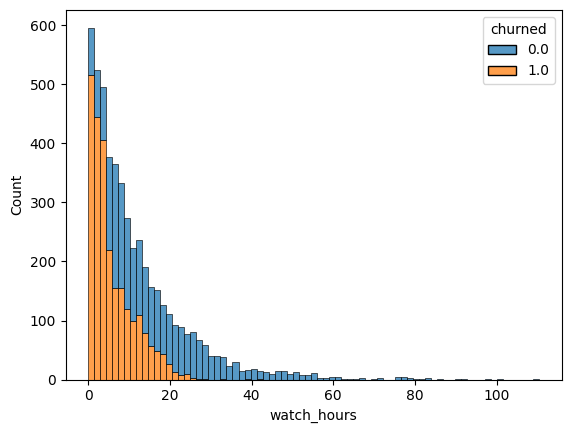

In [10]:
sns.histplot(data=df, x='watch_hours', hue='churned', multiple='stack')


In [11]:
## 0 -> 10 -- Casual Watcher
## 10 -> 20 -- Normal watcher
## 20 -> 60 -- heavy watcher
## 60+ -> Extreme Watcher

In [12]:
watch_hours = df[['watch_hours']]

In [13]:
casual = (watch_hours <= 10)  & (watch_hours > 0)
normal = (watch_hours <= 20)  & (watch_hours > 10)
heavy = (watch_hours <= 60)  & (watch_hours > 20)

In [14]:
new_df = df.copy()

In [15]:
new_df['watcher_type'] = np.where(casual, "Casual", 
        np.where(normal, "Normal",
                np.where(heavy, "Heavy", "Extreme")
            )
        )

In [16]:
new_df['watcher_type'].value_counts()

watcher_type
Casual     2920
Normal     1197
Heavy       847
Extreme      36
Name: count, dtype: int64

<Axes: xlabel='watcher_type', ylabel='Count'>

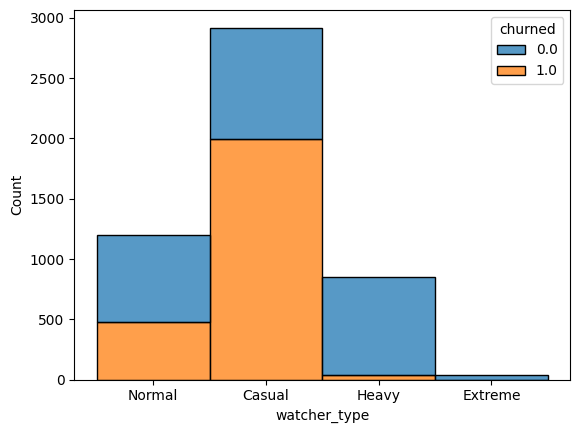

In [17]:
sns.histplot(data=new_df, x='watcher_type', hue='churned', multiple='stack')


In [18]:
watcher_mapping = {'Casual': 0, 'Normal': 1, 'Heavy': 2, 'Extreme': 3}
new_df['watcher_type'] = new_df['watcher_type'].map(watcher_mapping)



# Evaluation Time

In [19]:
X = df.drop(['churned'], axis = 1)
y = df['churned']

X_new = new_df.drop(['churned'], axis = 1)
y_new = new_df['churned']

In [27]:
np.round(np.mean(cross_val_score(LogisticRegression(max_iter=1000), X, y, scoring='roc_auc', cv =20)),3)

np.float64(0.967)

In [28]:
np.round(np.mean(cross_val_score(LogisticRegression(max_iter=1000), X_new, y_new, scoring='roc_auc', cv =20)),3)

np.float64(0.968)